# Homework 3 — Classification (ML Zoomcamp 2026)

Theory: [03-classification](https://github.com/DataTalksClub/machine-learning-zoomcamp/tree/main/03-classification)

Dataset: [course_lead_scoring_2026.csv](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)

Target: `converted` — did the lead sign up to the platform (**1**) or not (**0**).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mutual_info_score

df = pd.read_csv("course_lead_scoring_2026.csv")
print(df.shape)
display(df.head())

(5000, 9)


      lead_source       industry  ... lead_score converted
0  organic_search     technology  ...       0.64         1
1    social_media     technology  ...       0.72         1
2        referral         retail  ...       0.58         1
3        paid_ads  manufacturing  ...       0.57         0
4        referral  manufacturing  ...       0.62         1

[5 rows x 9 columns]

In [ ]:
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]

print(df.isna().sum())
print()
print(df.converted.value_counts(normalize=True).round(3))

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

converted
1    0.577
0    0.423
Name: proportion, dtype: float64


## Data preparation

Missing values are present, so:

* categorical features -> `'NA'`
* numerical features -> `0.0`

In [ ]:
df = df.copy()
df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

assert df.isna().sum().sum() == 0
print(df.isna().sum().sum(), "missing values left")

0 missing values left


## Question 1 — Mode for `industry`

In [ ]:
mode_industry = df["industry"].mode()[0]
print("mode:", mode_industry)
print()
print(df["industry"].value_counts())

mode: technology

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64


In [ ]:
# Answer: technology

## Question 2 — Biggest correlation among the numerical features

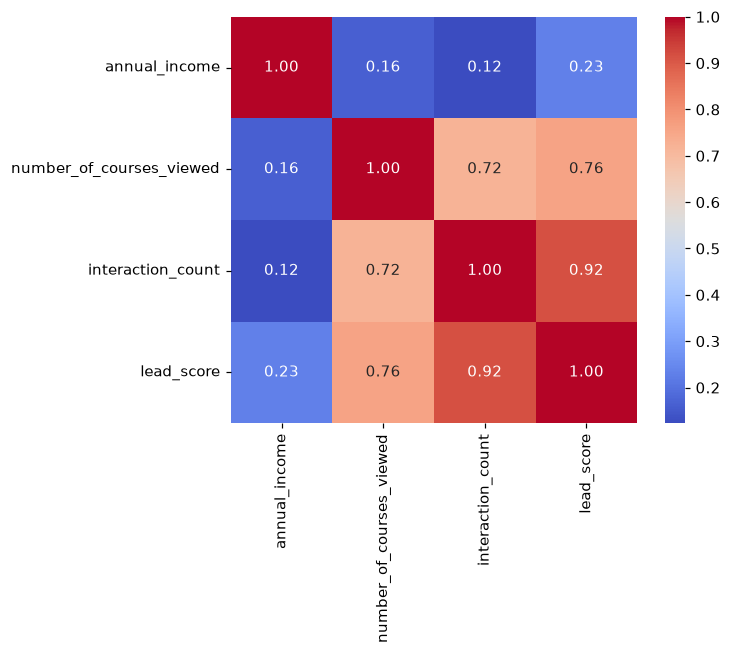

                          annual_income  ...  lead_score
annual_income                     1.000  ...       0.229
number_of_courses_viewed          0.161  ...       0.757
interaction_count                 0.123  ...       0.916
lead_score                        0.229  ...       1.000

[4 rows x 4 columns]

In [ ]:
corr = df[numerical].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
show(plt.gcf())
display(corr.round(3))

In [ ]:
pairs = [
    ("interaction_count", "lead_score"),
    ("number_of_courses_viewed", "lead_score"),
    ("number_of_courses_viewed", "interaction_count"),
    ("annual_income", "interaction_count"),
]

for a, b in pairs:
    print(f"{a:25s} vs {b:25s} -> {corr.loc[a, b]:.4f}")

best = max(pairs, key=lambda p: abs(corr.loc[p[0], p[1]]))
print("\nbiggest:", best)

interaction_count         vs lead_score                -> 0.9157
number_of_courses_viewed  vs lead_score                -> 0.7572
number_of_courses_viewed  vs interaction_count         -> 0.7216
annual_income             vs interaction_count         -> 0.1228

biggest: ('interaction_count', 'lead_score')


In [ ]:
# Answer: interaction_count and lead_score

## Split the data

In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

print("full:", len(df_full_train), "train:", len(df_train), "val:", len(df_val), "test:", len(df_test))

y_full_train = df_full_train["converted"].copy()
y_train = df_train["converted"].copy()
y_val = df_val["converted"].copy()

# make sure the target value `converted` is not in the dataframes
for d in (df_train, df_val, df_test, df_full_train):
    d.drop(columns=["converted"], inplace=True)

assert "converted" not in df_train.columns
assert "converted" not in df_val.columns

full: 4000 train: 3000 val: 1000 test: 1000


## Question 3 — Mutual information with `converted`

Training set only, rounded to 2 decimals.

In [ ]:
mis = {c: round(mutual_info_score(y_train, df_train[c]), 2) for c in categorical}
for k, v in sorted(mis.items(), key=lambda kv: -kv[1]):
    print(f"{k:20s} {v}")

best_mi = max(mis, key=mis.get)
print("\nbiggest MI:", best_mi)

lead_source          0.03
employment_status    0.02
industry             0.0
location             0.0

biggest MI: lead_source


In [ ]:
# Answer: lead_source

## Question 4 — Logistic regression accuracy

One-hot encode the categoricals with `DictVectorizer`, then:

`LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)`

In [ ]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(df_val[categorical + numerical].to_dict(orient="records"))

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

acc_full = accuracy_score(y_val, model.predict(X_val))
print("val accuracy:", round(acc_full, 2), "raw:", acc_full)

val accuracy: 0.65 raw: 0.645


In [ ]:
# Answer: 0.65

## Question 5 — Feature elimination

Train on all features, then drop one feature at a time and look at
`original_accuracy - accuracy_without_feature`. Smallest difference = least useful.

In [ ]:
def train_eval(cols, C=1.0):
    dv = DictVectorizer(sparse=False)
    Xtr = dv.fit_transform(df_train[cols].to_dict(orient="records"))
    Xva = dv.transform(df_val[cols].to_dict(orient="records"))
    m = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=42)
    m.fit(Xtr, y_train)
    return accuracy_score(y_val, m.predict(Xva))


all_features = categorical + numerical
diffs = {}
for f in ["lead_source", "number_of_courses_viewed", "interaction_count"]:
    cols = [c for c in all_features if c != f]
    a = train_eval(cols)
    diffs[f] = acc_full - a
    print(f"without {f:25s} acc={a:.4f}  diff={acc_full - a:+.4f}")

print("\nsmallest diff:", min(diffs, key=lambda k: diffs[k]))

without lead_source               acc=0.6420  diff=+0.0030
without number_of_courses_viewed  acc=0.6430  diff=+0.0020
without interaction_count         acc=0.6010  diff=+0.0440

smallest diff: number_of_courses_viewed


In [ ]:
# Answer: number_of_courses_viewed

## Question 6 — Regularization tuning (`C`)

In [ ]:
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    a = train_eval(all_features, C=C)
    print(f"C={C:<10g} acc={a:.6f}  rounded3={round(a, 3)}")

best_C = None
best_acc = -1
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    a = train_eval(all_features, C=C)
    if a > best_acc + 1e-12:
        best_acc, best_C = a, C
print("\nbest C:", best_C, "acc:", round(best_acc, 3))

C=1e-06      acc=0.598000  rounded3=0.598
C=1e-05      acc=0.598000  rounded3=0.598
C=0.0001     acc=0.613000  rounded3=0.613
C=0.001      acc=0.645000  rounded3=0.645

best C: 0.001 acc: 0.645


In [ ]:
# Answer: 0.001

## Answers

| # | Question | Answer |
|---|----------|--------|
| 1 | Mode for `industry` | `technology` |
| 2 | Biggest correlation | `interaction_count` and `lead_score` (0.92) |
| 3 | Biggest MI | `lead_source` (0.03) |
| 4 | Accuracy | `0.65` (raw 0.645) |
| 5 | Least useful feature | `number_of_courses_viewed` (diff 0.002) |
| 6 | Best `C` | `0.001` (0.645) |